This notebook attempts to use the kernel on a metric graph, comparing two OSMNX maps. The steet lenght must be normalized for the kernel to kind of work.

In [46]:
import sys, pathlib
sys.path.append(str(pathlib.Path().resolve().parent))
from src.graph_utils import plot_weighted_graph, compute_Q, ktte,kttw
from src.graph_dataset_preparation import load_mutag, add_uniform_weights, ensure_unique_edge_weights
import networkx as nx


In [ ]:
import osmnx as ox

# Center point (latitude, longitude)
center_point = (6.2090, -75.5658)  # Medellín (El Poblado-ish)

# Get a 2 km radius drivable network
G1 = ox.graph_from_point(
    center_point,
    dist=490,          # meters
    network_type="drive",
    simplify=True
)

print(type(G1))
print(len(G1.nodes), "nodes")
print(len(G1.edges), "edges")

<class 'networkx.classes.multidigraph.MultiDiGraph'>
124 nodes
212 edges


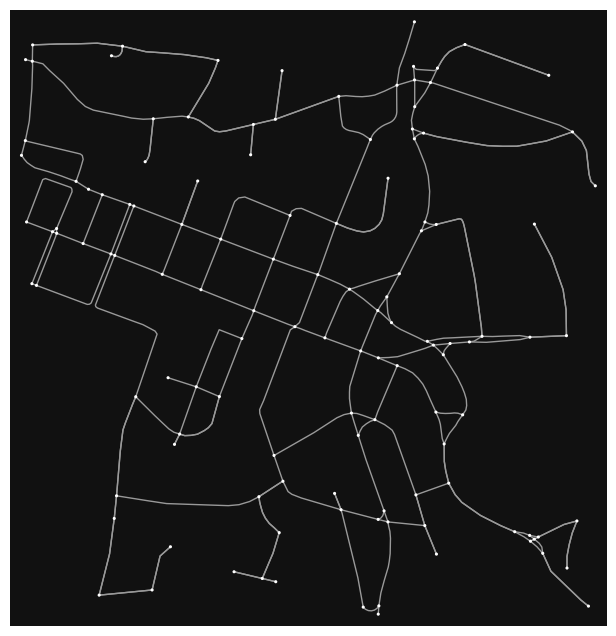

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [55]:
ox.plot_graph(G1, node_size=5)

In [56]:
# Center point (latitude, longitude)
center_point = (6.2083, -75.5656)  # Medellín (El Poblado-ish)

# Get a 2 km radius drivable network
G2 = ox.graph_from_point(
    center_point,
    dist=520,          # meters
    network_type="drive",
    simplify=True
)

print(type(G2))
print(len(G2.nodes), "nodes")
print(len(G2.edges), "edges")

<class 'networkx.classes.multidigraph.MultiDiGraph'>
127 nodes
219 edges


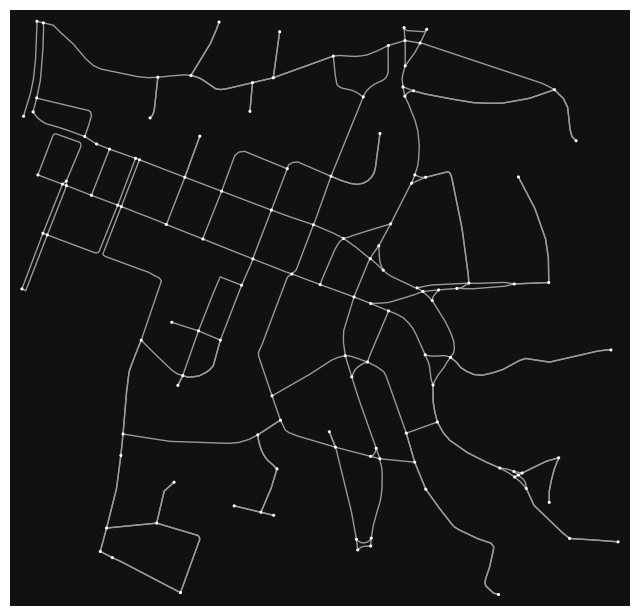

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [57]:
ox.plot_graph(G2, node_size=5)

In [59]:
G1_und = G1.to_undirected()
G2_und = G2.to_undirected()

In [60]:
Gu1 = nx.Graph()

for u, v, data in G1_und.edges(data=True):
    length = data.get("length", 1.0)
    if Gu1.has_edge(u, v):
        Gu1[u][v]["weight"] += length
    else:
        Gu1.add_edge(u, v, weight=length)


In [61]:
Gu2 = nx.Graph()

for u, v, data in G2_und.edges(data=True):
    length = data.get("length", 1.0)
    if Gu2.has_edge(u, v):
        Gu2[u][v]["weight"] += length
    else:
        Gu2.add_edge(u, v, weight=length)


In [62]:
Gu1_unique = ensure_unique_edge_weights([Gu1])
Gu2_unique = ensure_unique_edge_weights([Gu2])

In [63]:
def normalize_edge_weights(G, weight_attr="weight"):
    # Get maximum weight
    max_weight = max(
        data.get(weight_attr, 1)
        for _, _, data in G.edges(data=True)
    )
    
    # Avoid division by zero
    if max_weight == 0:
        return G

    # Normalize weights
    for u, v, data in G.edges(data=True):
        data[weight_attr] = data.get(weight_attr, 1) / max_weight

    return G


In [64]:
G1 = [normalize_edge_weights(Gu1_unique[0])]
G2 = [normalize_edge_weights(Gu2_unique[0])]


In [65]:
Q1 = compute_Q(G1[0])
Q2 = compute_Q(G2[0])

In [66]:
kt = ktte(Q1,Q2, gamma=0.001)
print(kt)

Forbenius Product 518.6470805076365
0.595325430756188


In [67]:
ktw = kttw(Q1,Q2, gamma=0.001)
print(ktw)

0.9674836534835075


/Users/gregorioperez/Documents/Maestria/Investigacion/graph kernels/src/graph_utils.py:367: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  sqrtQ1 = sqrtm(Q1)
/Users/gregorioperez/Documents/Maestria/Investigacion/graph kernels/src/graph_utils.py:369: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  sqrt_middle = sqrtm(middle)
